# Predicting Term Deposit Subscription Before the Call

A bank's call centre can only phone some of its customers about a term deposit. This notebook builds a model that ranks customers by their chance of subscribing, using only information available **before** a call is made, and measures how many subscribers the bank would reach by calling the top of the list.

Design choices that keep the evaluation honest:

1. **No call duration.** `duration` (length of the last call) is the strongest predictor in the data, but it is only known *after* a call ends and largely reflects the outcome, so it cannot help decide **whom to call**. It is excluded, and a separate run that includes it shows how much it would inflate the scores.
2. **Everything inside one pipeline.** Encoding, scaling, feature selection (`SelectKBest`) and the model sit in one scikit-learn `Pipeline`, fit on training folds only, so the test set never influences feature choice.
3. **Test set used once.** All hyperparameters are tuned by 5-fold cross-validation on the training set, optimising ROC AUC.

The notebook uses all 11,162 rows and ends with a **gains (lift) analysis** that answers the business question directly: *if the bank can only call some customers, who should it call?*

Results are summarised at the end.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score, RepeatedStratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, RocCurveDisplay
from sklearn.inspection import permutation_importance

SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")

## 2. Data and cleaning

Applied to all 11,162 rows:

- drop `contact`, `day` and `pdays` (uninformative or structurally missing)
- merge `poutcome = "other"` into `"failure"`
- encode the target `deposit` as 1 (yes) / 0 (no)

No rows are sampled away.

In [2]:
df = pd.read_csv("data/bank.csv")
print("Raw shape:", df.shape)

df = df.drop(columns=["contact", "day", "pdays"])
df["poutcome"] = df["poutcome"].replace({"other": "failure"})
df["deposit"] = (df["deposit"] == "yes").astype(int)

print("Clean shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Subscription rate: {:.1%}".format(df["deposit"].mean()))
df.head()

Raw shape: (11162, 17)
Clean shape: (11162, 14)
Missing values: 0
Subscription rate: 47.4%


,age,job,marital,education,default,balance,housing,loan,month,duration,campaign,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,may,1042,1,0,unknown,1
1,56,admin.,married,secondary,no,45,no,no,may,1467,1,0,unknown,1
2,41,technician,married,secondary,no,1270,yes,no,may,1389,1,0,unknown,1
3,55,services,married,secondary,no,2476,yes,no,may,579,1,0,unknown,1
4,54,admin.,married,tertiary,no,184,no,no,may,673,2,0,unknown,1


### Why `duration` has to go

The chart below shows how strongly call length separates the classes. That is exactly the problem: a long call is mostly a *consequence* of a customer who is interested and signing up, not something known in advance. The dataset's original documentation (UCI Bank Marketing, Moro et al. 2014) makes the same point and recommends dropping duration for a realistic predictive model.

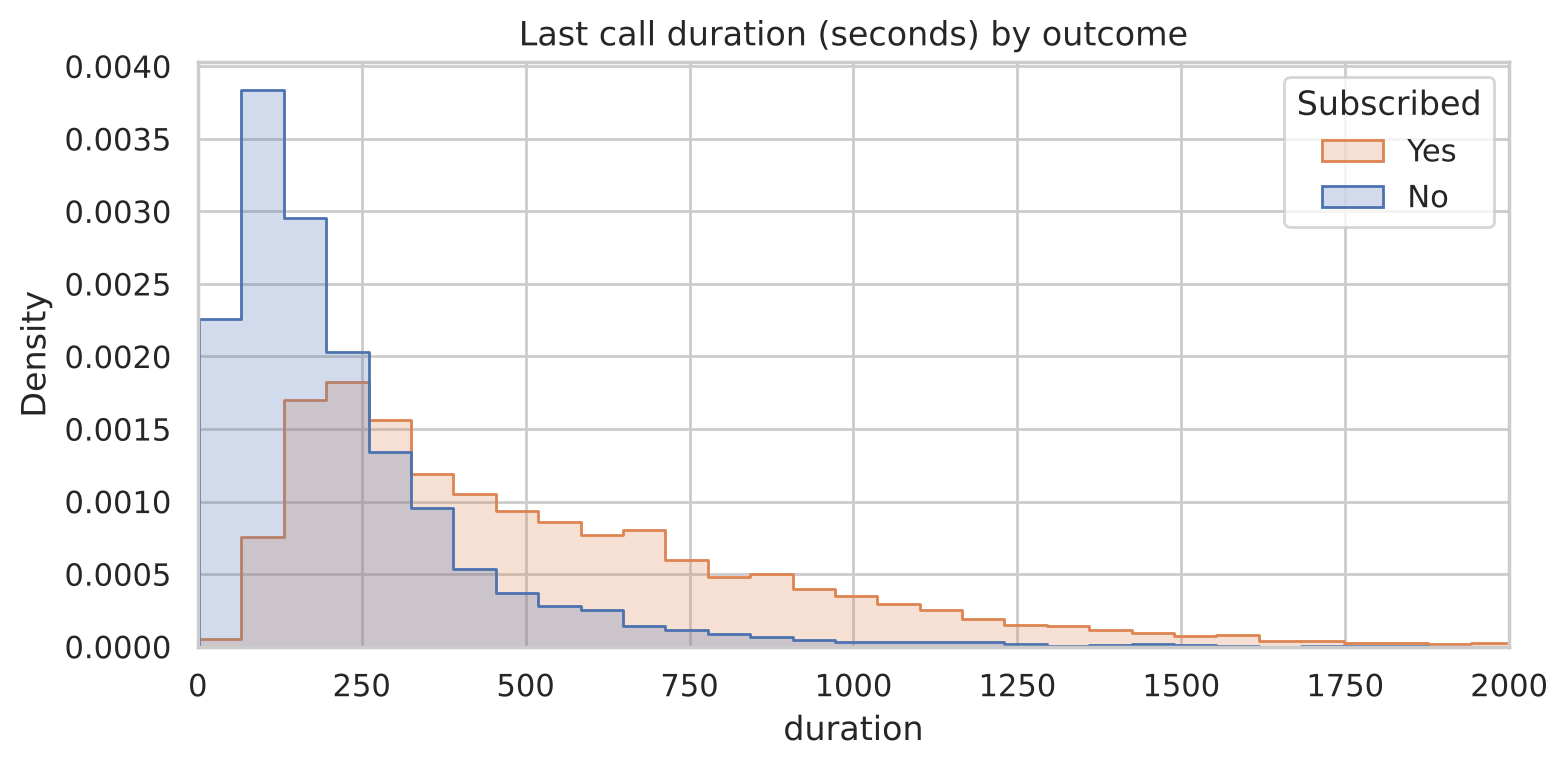

Median call length, subscribed:     426 s
Median call length, not subscribed: 163 s


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="duration", hue="deposit", bins=60, element="step", stat="density", common_norm=False, ax=ax)
ax.set_xlim(0, 2000)
ax.set_title("Last call duration (seconds) by outcome")
ax.legend(title="Subscribed", labels=["Yes", "No"])
plt.tight_layout(); plt.show()

print("Median call length, subscribed:     {:.0f} s".format(df.loc[df.deposit == 1, "duration"].median()))
print("Median call length, not subscribed: {:.0f} s".format(df.loc[df.deposit == 0, "duration"].median()))

## 3. Train/test split and preprocessing

- 80/20 stratified split, fixed seed. The test set is held out until section 6.
- Two feature sets are compared:
  - **Pre-call** (the usable model): everything except `duration`.
  - **With duration**: included only to measure how much the leak would inflate the scores.
- Preprocessing lives inside the pipeline: one-hot encoding for categoricals, standard scaling for numerics, then `SelectKBest` (ANOVA F) with *k* tuned by cross-validation.

In [4]:
y = df["deposit"]
X_all = df.drop(columns="deposit")
X_train_all, X_test_all, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, stratify=y, random_state=SEED)

FEATURE_SETS = {
    "Pre-call (no duration)": [c for c in X_all.columns if c != "duration"],
    "With duration (leaky)": list(X_all.columns),
}

def make_preprocessor(columns):
    cat = [c for c in columns if X_all[c].dtype == object or str(X_all[c].dtype).startswith("str")]
    num = [c for c in columns if c not in cat]
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
        ("num", StandardScaler(), num),
    ])

print("Train:", X_train_all.shape, " Test:", X_test_all.shape)
print("Pre-call features:", FEATURE_SETS["Pre-call (no duration)"])

Train: (8929, 13)  Test: (2233, 13)
Pre-call features: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'month', 'campaign', 'previous', 'poutcome']


## 4. Models and tuning

Seven model families: Logistic Regression, KNN, Decision Tree, Random Forest, SVM, a small feed-forward neural network (scikit-learn `MLPClassifier`, ReLU and Adam) and gradient boosting.

Every grid search uses 5-fold stratified CV on the training set and optimises ROC AUC.

In [5]:
MODELS = {
    "Logistic Regression": (LogisticRegression(solver="liblinear", max_iter=1000),
        {"clf__C": [0.01, 0.1, 1, 10], "clf__penalty": ["l1", "l2"]}),
    "KNN": (KNeighborsClassifier(),
        {"clf__n_neighbors": [5, 15, 31, 51], "clf__weights": ["uniform", "distance"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED),
        {"clf__max_depth": [3, 5, 8, 12], "clf__min_samples_leaf": [1, 10, 30]}),
    "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=-1),
        {"clf__n_estimators": [300], "clf__max_depth": [8, 16, None], "clf__min_samples_leaf": [1, 5]}),
    "SVM": (SVC(probability=True, random_state=SEED),
        {"clf__C": [0.3, 1, 3], "clf__kernel": ["rbf"], "clf__gamma": ["scale"]}),
    "Neural Network (MLP)": (MLPClassifier(max_iter=500, early_stopping=True, random_state=SEED),
        {"clf__hidden_layer_sizes": [(32,), (32, 16)], "clf__alpha": [1e-4, 1e-2]}),
    "Gradient Boosting": (HistGradientBoostingClassifier(random_state=SEED),
        {"clf__learning_rate": [0.05, 0.1], "clf__max_depth": [3, None], "clf__max_iter": [200]}),
}
K_GRID = [10, 20, "all"]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def tune(name, feature_set):
    cols = FEATURE_SETS[feature_set]
    est, grid = MODELS[name]
    pipe = Pipeline([("prep", make_preprocessor(cols)),
                     ("select", SelectKBest(f_classif)),
                     ("clf", est)])
    gs = GridSearchCV(pipe, {**grid, "select__k": K_GRID}, scoring="roc_auc", cv=CV, n_jobs=-1)
    gs.fit(X_train_all[cols], y_train)
    return gs

fitted = {}
for fs in FEATURE_SETS:
    for name in MODELS:
        fitted[(fs, name)] = tune(name, fs)
        print(f"{fs:<24} {name:<22} CV AUC = {fitted[(fs, name)].best_score_:.3f}  {fitted[(fs, name)].best_params_}")

Pre-call (no duration)   Logistic Regression    CV AUC = 0.743  {'clf__C': 0.1, 'clf__penalty': 'l2', 'select__k': 'all'}


Pre-call (no duration)   KNN                    CV AUC = 0.735  {'clf__n_neighbors': 51, 'clf__weights': 'distance', 'select__k': 'all'}


Pre-call (no duration)   Decision Tree          CV AUC = 0.724  {'clf__max_depth': 8, 'clf__min_samples_leaf': 30, 'select__k': 'all'}


Pre-call (no duration)   Random Forest          CV AUC = 0.757  {'clf__max_depth': 16, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 300, 'select__k': 'all'}


Pre-call (no duration)   SVM                    CV AUC = 0.750  {'clf__C': 0.3, 'clf__gamma': 'scale', 'clf__kernel': 'rbf', 'select__k': 'all'}


Pre-call (no duration)   Neural Network (MLP)   CV AUC = 0.750  {'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (32, 16), 'select__k': 'all'}


... (4 outputs left out)

With duration (leaky)    Random Forest          CV AUC = 0.906  {'clf__max_depth': 16, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 300, 'select__k': 'all'}


With duration (leaky)    SVM                    CV AUC = 0.905  {'clf__C': 1, 'clf__gamma': 'scale', 'clf__kernel': 'rbf', 'select__k': 'all'}


With duration (leaky)    Neural Network (MLP)   CV AUC = 0.902  {'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (32, 16), 'select__k': 'all'}


With duration (leaky)    Gradient Boosting      CV AUC = 0.908  {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__max_iter': 200, 'select__k': 'all'}


## 5. Cross-validated comparison (training data only)

In [6]:
cv_table = (pd.DataFrame([{"Feature set": fs, "Model": m, "CV AUC": gs.best_score_}
                          for (fs, m), gs in fitted.items()])
            .pivot(index="Model", columns="Feature set", values="CV AUC"))
cv_table["Drop when duration removed"] = cv_table["With duration (leaky)"] - cv_table["Pre-call (no duration)"]
cv_table = cv_table.sort_values("Pre-call (no duration)", ascending=False)
cv_table

Feature set,Pre-call (no duration),With duration (leaky),Drop when duration removed
Model,,,
Random Forest,0.757,0.906,0.148
Gradient Boosting,0.755,0.908,0.153
Neural Network (MLP),0.750,0.902,0.152
SVM,0.750,0.905,0.155
Logistic Regression,0.743,0.897,0.154
KNN,0.735,0.884,0.148
Decision Tree,0.724,0.877,0.153


**Is the best pre-call model really better than logistic regression?** With only a handful of folds, a plain paired t-test is overconfident because the folds share training data. Below, both models are scored on the same 10 × 5-fold splits and compared with the Nadeau and Bengio corrected resampled t-test.

In [7]:
precall = "Pre-call (no duration)"
best_name = cv_table["Pre-call (no duration)"].idxmax()
cols = FEATURE_SETS[precall]
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
s_best = cross_val_score(fitted[(precall, best_name)].best_estimator_, X_train_all[cols], y_train, scoring="roc_auc", cv=rcv, n_jobs=-1)
s_lr = cross_val_score(fitted[(precall, "Logistic Regression")].best_estimator_, X_train_all[cols], y_train, scoring="roc_auc", cv=rcv, n_jobs=-1)

d = s_best - s_lr
n = len(d); test_frac = 1 / 5
t = d.mean() / np.sqrt((1 / n + test_frac / (1 - test_frac)) * d.var(ddof=1))
p = 2 * stats.t.sf(abs(t), df=n - 1)
print(f"{best_name}: AUC {s_best.mean():.3f} ± {s_best.std():.3f}")
print(f"Logistic Regression: AUC {s_lr.mean():.3f} ± {s_lr.std():.3f}")
print(f"Mean difference {d.mean():+.3f}, corrected t = {t:.2f}, p = {p:.4f}")

Random Forest: AUC 0.756 ± 0.010
Logistic Regression: AUC 0.743 ± 0.011
Mean difference +0.013, corrected t = 4.21, p = 0.0001


## 6. Held-out test set (used once)

In [8]:
rows = []
for (fs, m), gs in fitted.items():
    fs_cols = FEATURE_SETS[fs]
    proba = gs.predict_proba(X_test_all[fs_cols])[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({"Feature set": fs, "Model": m,
                 "Test AUC": roc_auc_score(y_test, proba),
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})
test_table = pd.DataFrame(rows)
test_table.query("`Feature set` == @precall").drop(columns="Feature set").sort_values("Test AUC", ascending=False).set_index("Model")

,Test AUC,Accuracy,Precision,Recall,F1
Model,,,,,
Random Forest,0.763,0.711,0.768,0.560,0.647
Gradient Boosting,0.763,0.714,0.788,0.543,0.643
Neural Network (MLP),0.754,0.705,0.757,0.555,0.640
SVM,0.748,0.710,0.766,0.558,0.646
Logistic Regression,0.740,0.688,0.730,0.543,0.623
KNN,0.737,0.690,0.746,0.525,0.616
Decision Tree,0.727,0.685,0.797,0.449,0.574


In [9]:
print("With duration (for comparison only, not usable before a call):")
test_table.query("`Feature set` != @precall").drop(columns="Feature set").sort_values("Test AUC", ascending=False).set_index("Model")

With duration (for comparison only, not usable before a call):


,Test AUC,Accuracy,Precision,Recall,F1
Model,,,,,
Gradient Boosting,0.910,0.834,0.811,0.846,0.828
Random Forest,0.907,0.834,0.803,0.861,0.831
Neural Network (MLP),0.907,0.830,0.812,0.834,0.823
SVM,0.904,0.828,0.805,0.841,0.823
Logistic Regression,0.900,0.815,0.822,0.779,0.800
KNN,0.886,0.804,0.814,0.761,0.787
Decision Tree,0.879,0.795,0.747,0.859,0.799


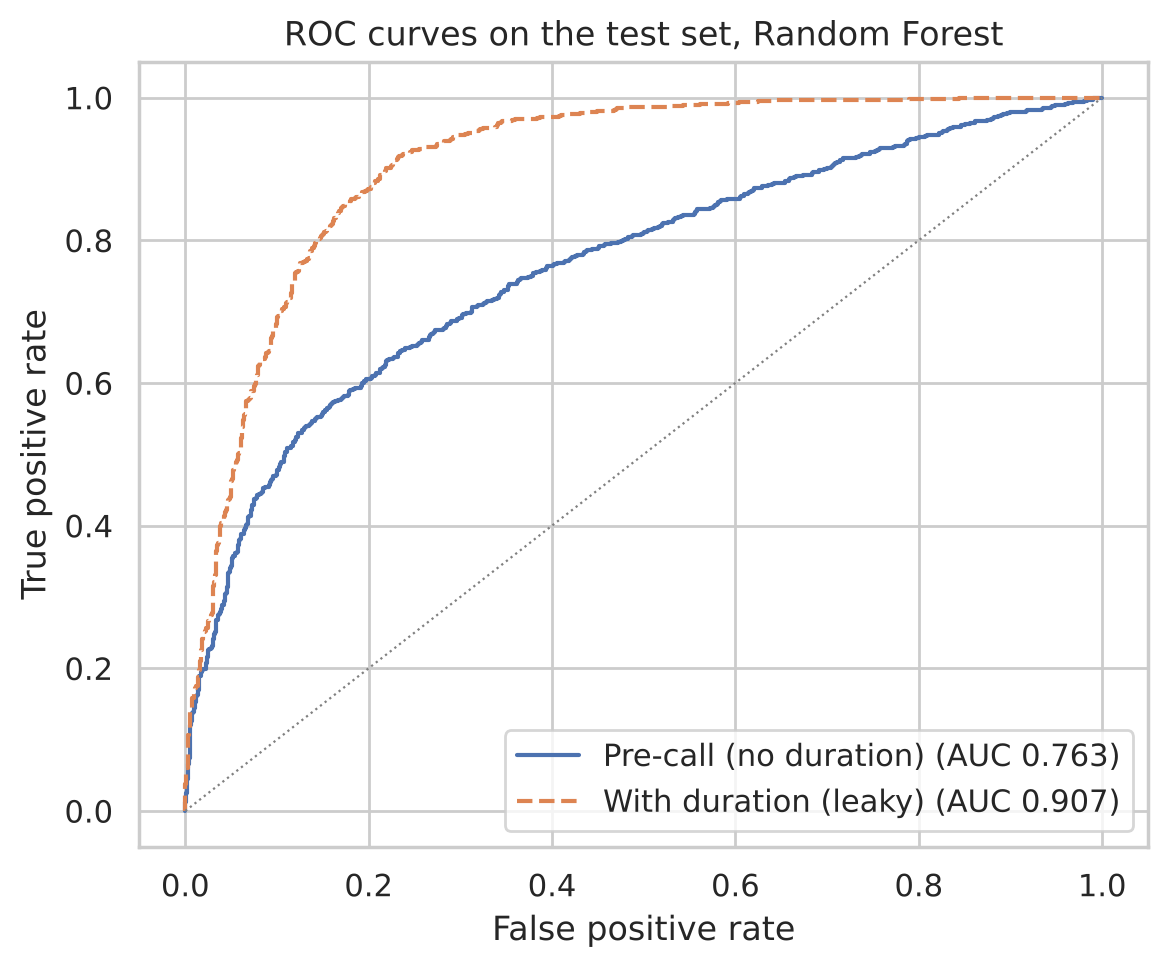

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
from sklearn.metrics import roc_curve
for fs, style in [(precall, "-"), ("With duration (leaky)", "--")]:
    gs = fitted[(fs, best_name)]
    p_ = gs.predict_proba(X_test_all[FEATURE_SETS[fs]])[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p_)
    ax.plot(fpr, tpr, linestyle=style, label=f"{fs} (AUC {roc_auc_score(y_test, p_):.3f})")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend(loc="lower right")
ax.plot([0, 1], [0, 1], color="grey", lw=0.8, linestyle=":")
ax.set_title(f"ROC curves on the test set, {best_name}")
plt.tight_layout(); plt.show()

## 7. Who should the bank call? Gains analysis

Accuracy at a 0.5 threshold is not how a call centre works. It has a limited number of calls and wants to spend them on the customers most likely to say yes. So the question is: if customers are ranked by predicted probability, what share of all subscribers is reached by calling the top 10%, 20%, 30%… of the list?

In [11]:
best = fitted[(precall, best_name)]
cols = FEATURE_SETS[precall]
proba = best.predict_proba(X_test_all[cols])[:, 1]
order = np.argsort(-proba)
y_sorted = y_test.to_numpy()[order]
n = len(y_sorted); base_rate = y_sorted.mean()

deciles = []
for pct in range(10, 101, 10):
    k = int(round(n * pct / 100))
    hits = y_sorted[:k].sum()
    deciles.append({"Top % called": pct,
                    "Customers called": k,
                    "Subscribers reached": int(hits),
                    "Share of all subscribers": hits / y_sorted.sum(),
                    "Hit rate in group": hits / k,
                    "Lift vs random": (hits / k) / base_rate})
gains = pd.DataFrame(deciles).set_index("Top % called")
gains

,Customers called,Subscribers reached,Share of all subscribers,Hit rate in group,Lift vs random
Top % called,,,,,
10,223,203,0.192,0.910,1.921
20,447,383,0.362,0.857,1.808
30,670,538,0.509,0.803,1.695
40,893,648,0.612,0.726,1.532
50,1116,747,0.706,0.669,1.413
60,1340,829,0.784,0.619,1.306
70,1563,893,0.844,0.571,1.206
80,1786,956,0.904,0.535,1.130
90,2010,1016,0.960,0.505,1.067


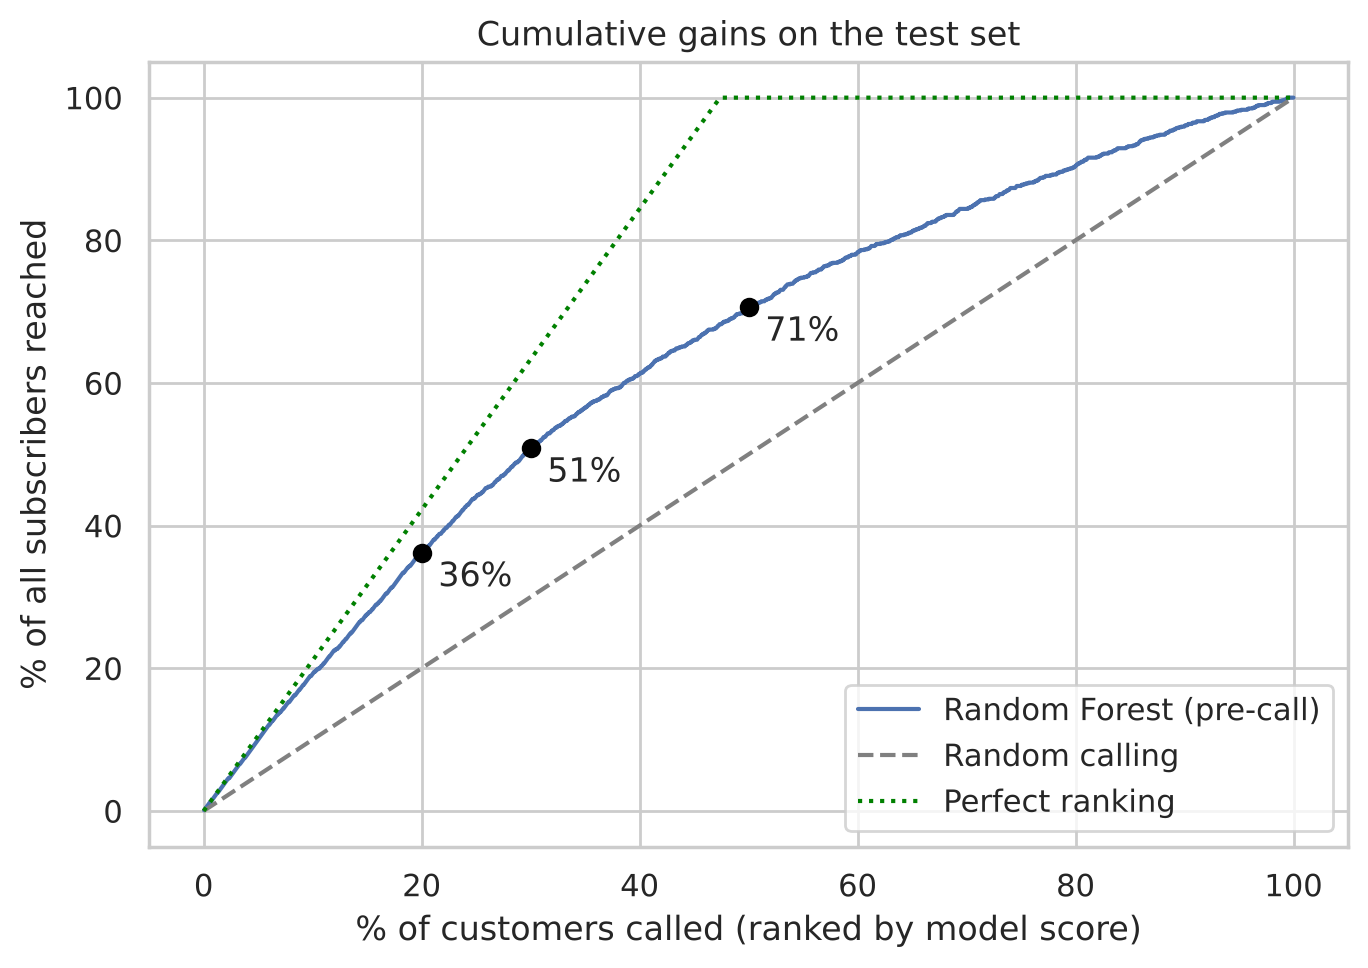

In [12]:
x = np.arange(1, n + 1) / n
captured = np.cumsum(y_sorted) / y_sorted.sum()
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x * 100, captured * 100, label=f"{best_name} (pre-call)")
ax.plot([0, 100], [0, 100], color="grey", linestyle="--", label="Random calling")
ax.plot([0, base_rate * 100, 100], [0, 100, 100], color="green", linestyle=":", label="Perfect ranking")
for pct in (20, 30, 50):
    v = gains.loc[pct, "Share of all subscribers"] * 100
    ax.scatter([pct], [v], color="black", zorder=3)
    ax.annotate(f"{v:.0f}%", (pct, v), textcoords="offset points", xytext=(6, -12))
ax.set_xlabel("% of customers called (ranked by model score)")
ax.set_ylabel("% of all subscribers reached")
ax.set_title("Cumulative gains on the test set")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 8. What drives the pre-call model?

Permutation importance on the test set: how much test AUC falls when one input column is shuffled. This is measured on raw columns (before one-hot encoding), so each bar is one business variable.

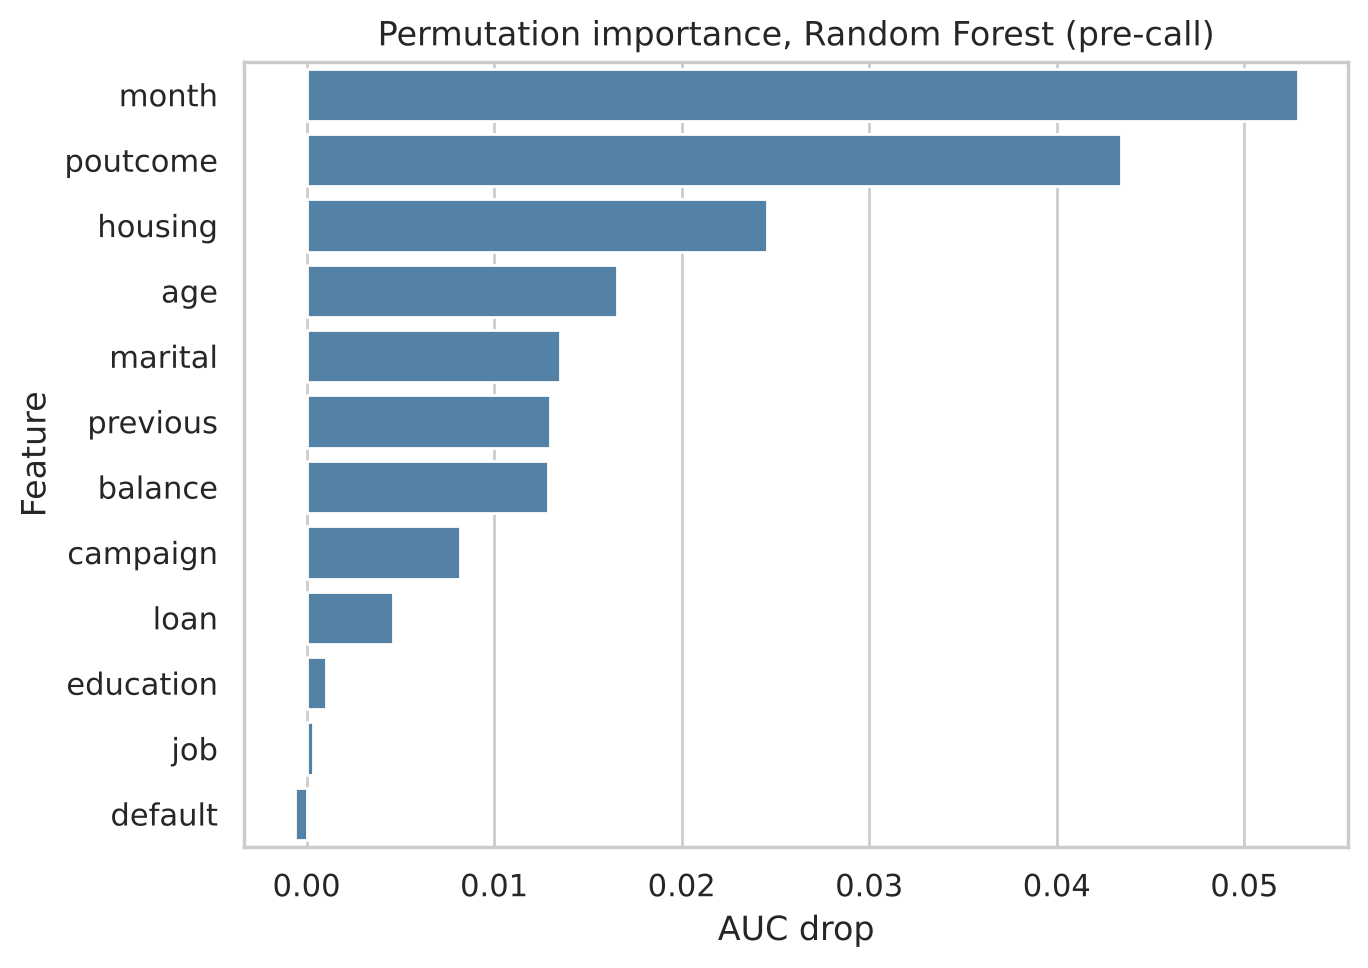

,AUC drop,sd
Feature,,
month,5.285e-02,4.421e-03
poutcome,4.345e-02,5.541e-03
housing,2.455e-02,4.398e-03
age,1.656e-02,4.200e-03
marital,1.349e-02,3.189e-03
previous,1.296e-02,3.859e-03
balance,1.286e-02,2.968e-03
campaign,8.185e-03,1.929e-03
loan,4.602e-03,2.008e-03


In [13]:
imp = permutation_importance(best, X_test_all[cols], y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
imp_df = pd.DataFrame({"Feature": cols, "AUC drop": imp.importances_mean, "sd": imp.importances_std}).sort_values("AUC drop", ascending=False)
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=imp_df, x="AUC drop", y="Feature", color="steelblue", ax=ax)
ax.set_title(f"Permutation importance, {best_name} (pre-call)")
plt.tight_layout(); plt.show()
imp_df.set_index("Feature")

## 9. Summary

In [14]:
pre = test_table.query("`Feature set` == @precall").set_index("Model")
leak = test_table.query("`Feature set` != @precall").set_index("Model")
print(f"Best pre-call model: {best_name}")
print(f"  Test AUC {pre.loc[best_name, 'Test AUC']:.3f}, accuracy {pre.loc[best_name, 'Accuracy']:.3f}")
print(f"  Same model with duration: test AUC {leak.loc[best_name, 'Test AUC']:.3f}, accuracy {leak.loc[best_name, 'Accuracy']:.3f}")
print(f"  Calling the top 20% reaches {gains.loc[20, 'Share of all subscribers']:.0%} of subscribers "
      f"(hit rate {gains.loc[20, 'Hit rate in group']:.0%} vs {base_rate:.0%} base rate, lift {gains.loc[20, 'Lift vs random']:.2f})")
print(f"  Calling the top 50% reaches {gains.loc[50, 'Share of all subscribers']:.0%} of subscribers")

Best pre-call model: Random Forest
  Test AUC 0.763, accuracy 0.711
  Same model with duration: test AUC 0.907, accuracy 0.834
  Calling the top 20% reaches 36% of subscribers (hit rate 86% vs 47% base rate, lift 1.81)
  Calling the top 50% reaches 71% of subscribers


### Limitations

- **This dataset is balanced (47% subscribed).** The original UCI campaign data has a subscription rate of about 11%, so this Kaggle version was resampled. Absolute hit rates would be much lower in a real campaign; the ranking and lift logic still apply.
- **`campaign` and `previous`** count contacts made so far, which are known when the next call is planned, so they are kept. `month` is the month of the last contact and is also known at planning time.
- **No cost data.** With a cost per call and a value per deposit, the gains table converts directly into the number of customers worth calling.